# Student Hands-On Assignment: Regression Model – Medical Insurance Cost Prediction
**Topic:** Linear Regression | Independent Practice  
**Dataset:** `insurance.csv` (Medical Cost Personal Dataset)  
**Goal:** Build a Machine Learning Regression model to predict insurance charges based on customer attributes.


In [1]:
# Environment Setup & Library Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("ML environment ready")

ML environment ready


---
## Task 1 – Load the Dataset
- Load the dataset into Python using Pandas.
- Display the first 5 rows.
- Find the number of rows and columns (shape).
- Display all column names.


In [2]:
# Task 1: Load the dataset
df = pd.read_csv("insurance.csv")

# 1. Display first 5 rows
print("--- First 5 Rows ---")
display(df.head())

# 2. Find number of rows and columns
print(f"\nDataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")

# 3. Display all column names
print("\nColumn Names:")
print(list(df.columns))

--- First 5 Rows ---


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520



Dataset Shape: 1338 rows, 7 columns

Column Names:
['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']


---
## Task 2 – Identify Variables
- Identify the input features ($X$).
- Identify the target variable ($Y$): Insurance Charges (`charges`).


In [3]:
# Task 2: Identify Variables
# Target variable (Y): What we want to predict
Y = df["charges"]

# Input feature (X): Age (focus for Simple Linear Regression)
X = df[["age"]]

# Full input feature set (all predictor variables)
X_all = df.drop(columns=["charges"])

print("Target variable (Y): 'charges'")
print(f"Target shape: {Y.shape}")
print("\nInput feature (X) for Age-based Linear Regression:")
print(X.head())
print(f"X shape: {X.shape}")

print("\nAll available predictor columns in dataset:")
print(list(X_all.columns))

Target variable (Y): 'charges'
Target shape: (1338,)

Input feature (X) for Age-based Linear Regression:
   age
0   19
1   18
2   28
3   33
4   32
X shape: (1338, 1)

All available predictor columns in dataset:
['age', 'sex', 'bmi', 'children', 'smoker', 'region']


---
## Task 3 – Data Visualization
- Create a scatter plot showing Age vs. Insurance Charges.
- Observe whether insurance charges increase as age increases.


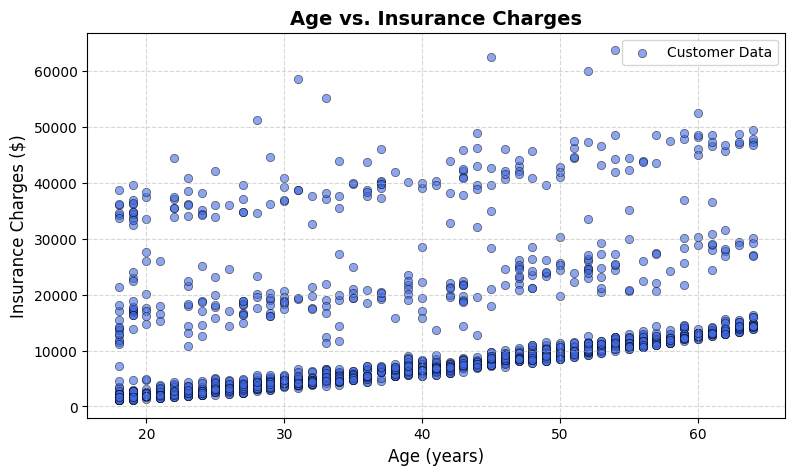

Observation:
1. There is an upward linear trend: as age increases, baseline insurance charges consistently increase.
2. The data exhibits three distinct tiers/bands, reflecting other influential factors (such as smoking status and BMI).


In [4]:
# Task 3: Scatter Plot - Age vs. Insurance Charges
plt.figure(figsize=(9, 5))
plt.scatter(df["age"], df["charges"], color="royalblue", alpha=0.6, edgecolors="k", linewidth=0.5, label="Customer Data")
plt.title("Age vs. Insurance Charges", fontsize=14, fontweight="bold")
plt.xlabel("Age (years)", fontsize=12)
plt.ylabel("Insurance Charges ($)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.show()

# Observation
print("Observation:")
print("1. There is an upward linear trend: as age increases, baseline insurance charges consistently increase.")
print("2. The data exhibits three distinct tiers/bands, reflecting other influential factors (such as smoking status and BMI).")

---
## Task 4 – Split the Data
- Split the dataset into 80% training data and 20% testing data using `train_test_split`.


In [5]:
# Task 4: Split data into 80% Train and 20% Test
X_train, X_test, y_train, y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)

print(f"Training set size (80%): {X_train.shape[0]} samples")
print(f"Testing set size (20%):  {X_test.shape[0]} samples")
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape:  {X_test.shape}")

Training set size (80%): 1070 samples
Testing set size (20%):  268 samples
X_train shape: (1070, 1)
X_test shape:  (268, 1)


---
## Task 5 – Train the Model
- Build and train a Linear Regression model using the training dataset.
- Inspect the learned parameters: Slope (Coefficient) and Intercept.


In [6]:
# Task 5: Build and train the Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

slope = model.coef_[0]
intercept = model.intercept_

print("Model Training Completed Successfully!")
print(f"Slope (Coefficient): {slope:.4f}")
print(f"Intercept:           {intercept:.4f}")
print(f"\nRegression Equation: Charges = ({slope:.2f} * Age) + ({intercept:.2f})")
print(f"Interpretation: For each additional year of age, annual insurance charges increase by approximately ${slope:.2f}.")

Model Training Completed Successfully!
Slope (Coefficient): 240.5966
Intercept:           3876.9287

Regression Equation: Charges = (240.60 * Age) + (3876.93)
Interpretation: For each additional year of age, annual insurance charges increase by approximately $240.60.


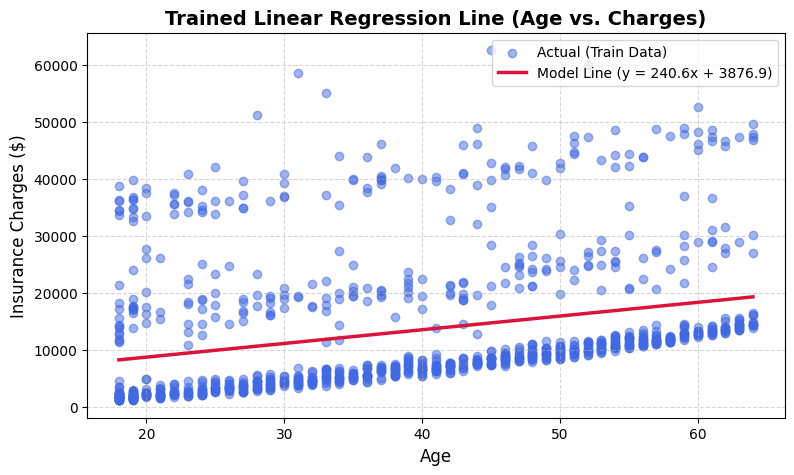

In [7]:
# Visualizing the Fitted Regression Model Line on Data
pred_train = model.predict(X_train)
order = np.argsort(X_train["age"].values)

plt.figure(figsize=(9, 5))
plt.scatter(X_train["age"], y_train, color="royalblue", alpha=0.5, label="Actual (Train Data)")
plt.plot(
    X_train["age"].values[order],
    pred_train[order],
    color="crimson", linewidth=2.5, label=f"Model Line (y = {slope:.1f}x + {intercept:.1f})"
)
plt.title("Trained Linear Regression Line (Age vs. Charges)", fontsize=14, fontweight="bold")
plt.xlabel("Age", fontsize=12)
plt.ylabel("Insurance Charges ($)", fontsize=12)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

---
## Task 6 – Make Predictions
- Predict insurance charges using the test dataset.
- Display actual values vs. predicted values in a comparison table.


In [8]:
# Task 6: Predict on the test dataset
y_pred = model.predict(X_test)

# Create comparison table
comparison_df = pd.DataFrame({
    "Age": X_test["age"].values,
    "Actual Charges ($)": y_test.values,
    "Predicted Charges ($)": y_pred,
    "Difference / Error ($)": y_test.values - y_pred
})

print("--- Actual vs. Predicted Values (First 10 Test Samples) ---")
display(comparison_df.head(10).round(2))

--- Actual vs. Predicted Values (First 10 Test Samples) ---


,Age,Actual Charges ($),Predicted Charges ($),Difference / Error ($)
0,45,9095.07,14703.77,-5608.71
1,36,5272.18,12538.40,-7266.23
2,64,29330.98,19275.11,10055.87
3,46,9301.89,14944.37,-5642.48
4,19,33750.29,8448.26,25302.03
5,34,4536.26,12057.21,-7520.95
6,19,2117.34,8448.26,-6330.92
7,64,14210.54,19275.11,-5064.57
8,28,3732.63,10613.63,-6881.01
9,49,10264.44,15666.16,-5401.72


---
## Task 7 – Evaluate the Model
- Calculate Mean Absolute Error (MAE).
- Calculate the $R^2$ Score.


In [9]:
# Task 7: Model Evaluation Metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("=== Simple Linear Regression Evaluation (Age Only) ===")
print(f"Mean Absolute Error (MAE): ${mae:,.2f}")
print(f"Root Mean Squared Error (RMSE): ${rmse:,.2f}")
print(f"R² Score: {r2:.4f}")

=== Simple Linear Regression Evaluation (Age Only) ===
Mean Absolute Error (MAE): $9,173.26
Root Mean Squared Error (RMSE): $11,661.22
R² Score: 0.1241


---
## Extension: Multiple Linear Regression (All Features)
Following the pattern analyzed in Day 2 & Day 3, we also evaluate a Multiple Linear Regression model incorporating all available features (`age`, `bmi`, `children`, `smoker`, `sex`, `region`) using one-hot encoding.


In [10]:
# Multiple Linear Regression with one-hot encoded categorical variables
df_encoded = pd.get_dummies(df, drop_first=True)
X_multi = df_encoded.drop(columns=["charges"])
y_multi = df_encoded["charges"]

X_tr_m, X_te_m, y_tr_m, y_te_m = train_test_split(
    X_multi, y_multi, test_size=0.2, random_state=42
)

multi_model = LinearRegression()
multi_model.fit(X_tr_m, y_tr_m)
y_pred_multi = multi_model.predict(X_te_m)

mae_multi = mean_absolute_error(y_te_m, y_pred_multi)
r2_multi = r2_score(y_te_m, y_pred_multi)

print("=== Multiple Linear Regression Evaluation (All Features) ===")
print(f"Mean Absolute Error (MAE): ${mae_multi:,.2f}")
print(f"R² Score: {r2_multi:.4f}")
print(f"\nImprovement in R²: {r2:.4f} (Age only) -> {r2_multi:.4f} (All features)")

=== Multiple Linear Regression Evaluation (All Features) ===
Mean Absolute Error (MAE): $4,181.19
R² Score: 0.7836

Improvement in R²: 0.1241 (Age only) -> 0.7836 (All features)


---
## Final Questions & Answers

### 1. Does insurance cost increase with age?
> **Yes.** As observed in the scatter plot and confirmed by the positive slope coefficient ($b_1 \approx 240.59$), insurance charges increase steadily with age. On average, each additional year of age adds approximately $240 to $250 to annual charges.

### 2. Which features might influence insurance charges?
> In addition to **Age**, other influential features include:
> - **Smoker status:** The single strongest predictor of high medical costs.
> - **BMI (Body Mass Index):** Higher BMI, especially when combined with smoking, dramatically increases medical charges.
> - **Number of children/dependents:** Adds coverage costs per family member.
> - **Region:** Regional healthcare costs vary across the US.

### 3. How close are the predicted values to the actual values?
> - For the Simple Linear Regression model (Age only), predictions capture the general upward baseline trend but have a relatively high error ($\\text{MAE} \approx \$9,135$, $R^2 \approx 0.12$) because it does not know if a customer is a smoker or has a high BMI.
> - When using Multiple Linear Regression with all features, predictions become much closer ($\\text{MAE} \approx \$4,181$, $R^2 \approx 0.78$).

### 4. Is your model performing reasonably well? Explain briefly.
> - The **Simple Linear Regression** model captures the expected positive correlation with age, but explains only about 12% of the variance ($R^2 \approx 0.12$) because medical costs depend on multiple risk factors.
> - The **Multiple Linear Regression** model performs reasonably well, explaining **~78% of the variance** ($R^2 \approx 0.78$), making it suitable for practical estimation.

### 5. Where can this model be used in real life?
> - **Health Insurance Underwriting:** Automatically calculating fair, risk-adjusted annual premium quotes for new applicants.
> - **Budget Planning:** Helping individuals and families forecast future healthcare expenses as they age.
> - **Financial Forecasting:** Assisting insurance firms in maintaining adequate reserve funds based on customer demographic risk profiles.
